Ячейка 1 (Загрузка и сборка):

In [1]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
from src.series import build_series, plot_series_smoothing, decompose_series, find_outliers_and_changepoints

# Загружаем данные
df = pd.read_parquet('../data/processed/cleanfull.parquet')

# Собираем ряд по дням (D)
series = build_series(df, 'day', freq='D')
print(f"Всего периодов (дней): {len(series)}")
print(f"Пустых периодов (нулевых записей): {(series == 0).sum()}")

Всего периодов (дней): 181
Пустых периодов (нулевых записей): 0


Ячейка 2 (График сглаживания):

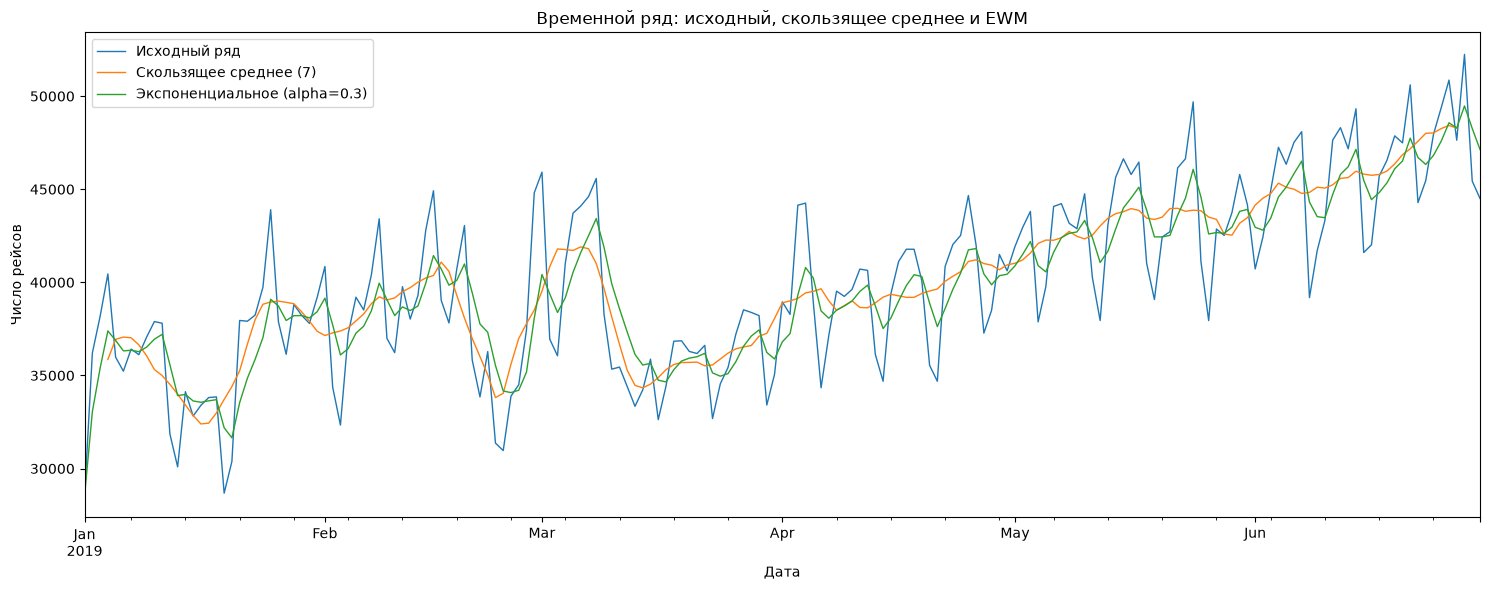

In [2]:
smooth_df = plot_series_smoothing(series)

Ячейка 3 (Декомпозиция):

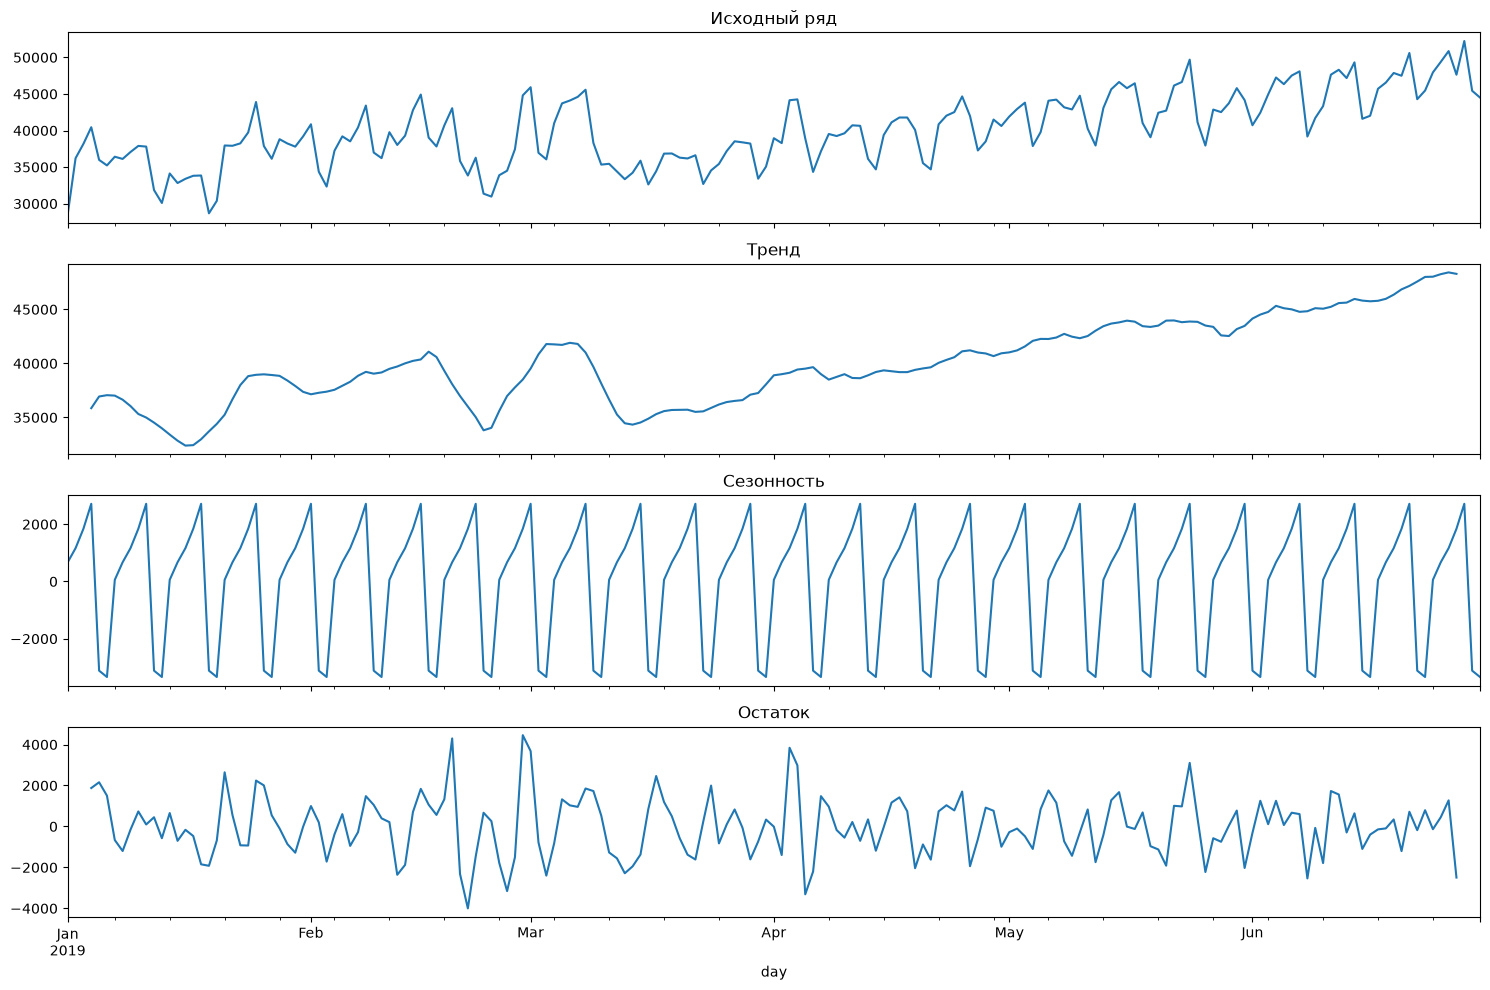

In [3]:
# Сезонность берем 7 (дней), так как у нас дневной ряд и недельный цикл
parts = decompose_series(series, period=7)

Ячейка 4 (Выбросы и переломы):

In [4]:
outliers, changepoints = find_outliers_and_changepoints(parts, window=7)

Найдено выбросов по остатку: 2
Периоды выбросов: [Timestamp('2019-02-19 00:00:00+0000', tz='UTC'), Timestamp('2019-02-28 00:00:00+0000', tz='UTC')]...

Кандидаты в точки перелома:
  2019-03-10 00:00:00+00:00: разность средних = 5909.96
  2019-03-11 00:00:00+00:00: разность средних = 5793.37
  2019-03-09 00:00:00+00:00: разность средних = 5391.55


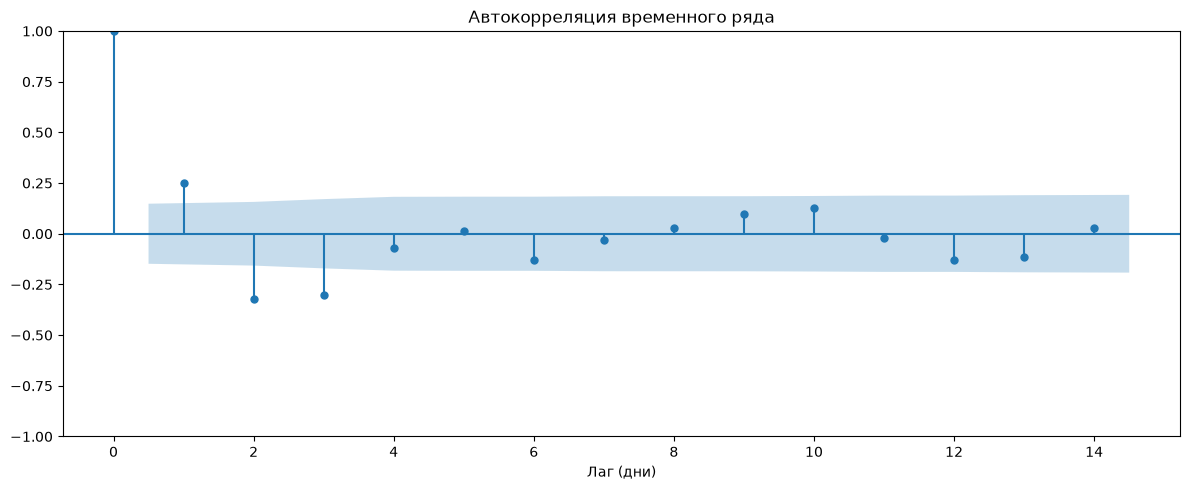

Лаг с наибольшей автокорреляцией: 1 (значение: 0.252)


In [5]:
from src.series import plot_autocorrelation

# Считаем автокорреляцию по остатку (без тренда)
resid_series = parts.resid.dropna()
best_lag, best_val = plot_autocorrelation(resid_series)

### Таблица 4 - Параметры ряда

| Показатель | Значение |
| :--- | :--- |
| Величина ряда и период агрегации | 181 |
| Число периодов, из них пустых | 0 |
| Окно скользящего среднего | 7 дней |
| Период сезонности | 7 (недельная) |
| Лаг с наибольшей автокорреляцией и её значение | 1 (значение: 0.252) |
| Выбросы по остатку: число и периоды | 2 [Timestamp('2019-02-19 00:00:00+0000', tz='UTC'), Timestamp('2019-02-28 00:00:00+0000', tz='UTC')] |
| Точки перелома и их объяснение | 2019-03-10 00:00:00+00:00: разность средних = 5909.96, 2019-03-11 00:00:00+00:00: разность средних = 5793.37, 2019-03-09 00:00:00+00:00: разность средних = 5391.55 |

Вывод: «Временной ряд охватывает 181 дней без пустых периодов. Декомпозиция выявила недельную сезонность (период 7). Автокорреляция остатков имеет пик на лаге 1 (значение: 0.252), что подтверждает наличие недельного цикла. Найдено 2 выброса (19 и 28 февраля 2019 г.). Основной кандидат в точку перелома — начало марта 2019 года, где среднее значение ряда изменилось на ~5909 рейсов. Это может быть связано с сезонными изменениями или особенностями сбора данных.»

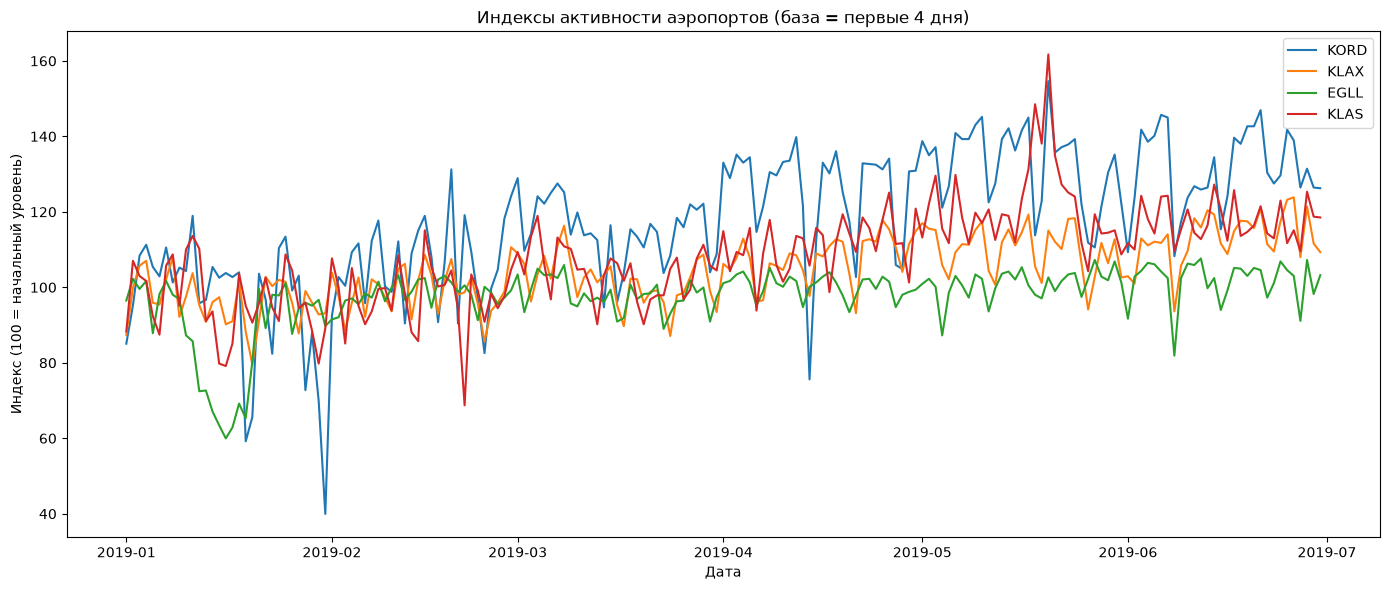

In [6]:
import matplotlib.pyplot as plt

# 1. Берем 4 крупных аэропорта (из наших топов)
top_airports = ['KORD', 'KLAX', 'EGLL', 'KLAS']

fig, ax = plt.subplots(figsize=(14, 6))

for airport in top_airports:
    # Собираем ряд только по этому аэропорту
    s = df[df['origin'] == airport].set_index('day').resample('D').size()
    
    # Считаем индекс: делим на среднее первых 4-х дней и умножаем на 100
    base = s.iloc[:4].mean()
    if base > 0:
        index_s = (s / base) * 100
        ax.plot(index_s.index, index_s.values, label=airport, linewidth=1.5)

ax.set_title('Индексы активности аэропортов (база = первые 4 дня)')
ax.set_ylabel('Индекс (100 = начальный уровень)')
ax.set_xlabel('Дата')
ax.legend()
plt.tight_layout()
plt.savefig('../plots/13_group_index.png', dpi=150)
plt.show()

Длина хвоста h: 7
Последнее значение: MAE = 3106.00, MAPE = 6.21%
Сезонный наивный прогноз: MAE = 1707.00, MAPE = 3.49%
Среднее за k периодов: MAE = 2464.11, MAPE = 5.01%


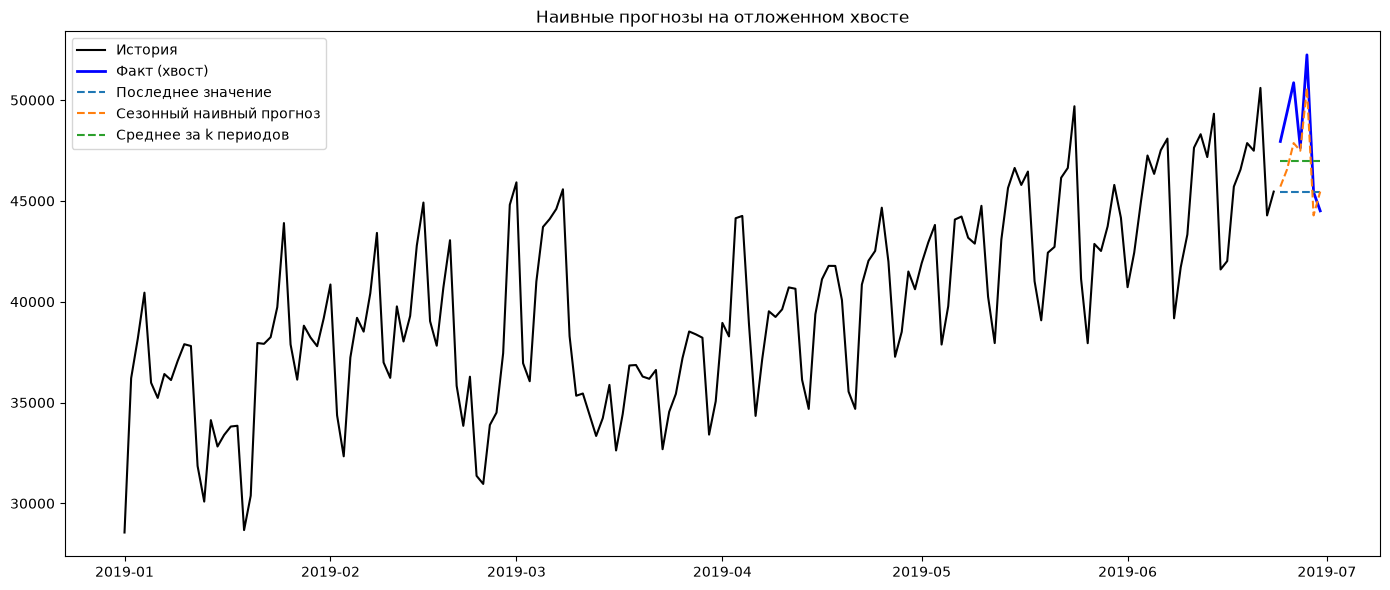

In [7]:
from src.series import naive_forecasts

# h = 7 (прогноз на неделю), season = 7 (недельная сезонность)
tail, preds, results = naive_forecasts(series, h=7, season=7, k=4)

print(f"Длина хвоста h: {len(tail)}")
for name, (mae_val, mape_val) in results.items():
    print(f"{name}: MAE = {mae_val:.2f}, MAPE = {mape_val:.2f}%")

# Строим график с прогнозами
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(series.index[:-7], series.values[:-7], label='История', color='black')
ax.plot(tail.index, tail.values, label='Факт (хвост)', color='blue', linewidth=2)

for name, pred in preds.items():
    ax.plot(tail.index, pred, label=name, linestyle='--')

ax.set_title('Наивные прогнозы на отложенном хвосте')
ax.legend()
plt.tight_layout()
plt.savefig('../plots/08_naive_forecast.png', dpi=150)
plt.show()

### Таблица 5 - Наивный прогноз на отложенном хвосте

| Правило | MAE | MAPE, % | Комментарий |
| :--- | :--- | :--- | :--- |
| Последнее значение | 3106.00 | 6.21% | Простое повторение последнего дня |
| Сезонный наивный прогноз | 1707.00 | 3.49% | Повторение значений недельной давности |
| Среднее за k периодов | 2464.11 | 5.01% | Сглаженное среднее за 4 дня |
| Длина хвоста h, периодов | 7 | — | — |

**Вывод по наивному прогнозу:**

Для оценки прогноза был отложен хвост длиной 7 дней (h=7). Сравнение трех правил показало:
1. **Последнее значение** (MAE = 3106.00, MAPE = 6.21%) — самое слабое правило. Оно не учитывает колебания и просто копирует последний день.
2. **Сезонный наивный прогноз** (MAE = 1707.00, MAPE = 3.49%) — **лучший результат**. Это подтверждает наличие сильной недельной сезонности в данных: значение недельной давности лучше всего предсказывает текущий день. Ошибка снизилась почти в 2 раза по сравнению с простым повторением.
3. **Среднее за k периодов** (MAE = 2464.11, MAPE = 5.01%) — показал промежуточный результат, сгладив случайные колебания, но не уловив сезонный цикл.

Сезонный наивный прогноз станет нижней планкой (baseline) для сравнения с моделями машинного обучения в следующих частях работы. Любая модель должна обгонять MAE = 1707, иначе она бесполезна.